# Ingeniería de Características (`features_proyecto.ipynb`) — OralSolutions

## 1. Definición del Problema y Momento Exacto de Predicción

* **Qué predice el modelo:** Clasificación binaria de la probabilidad de abandono de tratamiento a 60 días (`abandono_60d`):
  * `1` (**Abandona**): El paciente **no** completa una siguiente sesión dentro del mismo plan de tratamiento en los 60 días posteriores a la sesión actual.
  * `0` (**Continúa**): El paciente sí asiste y completa su siguiente sesión programada dentro de esa ventana de 60 días.
* **Instante exacto de inferencia (corte temporal):** La predicción se ejecuta **al cierre de cada sesión clínica atendida** (`fecha_realizada`), únicamente cuando el plan de tratamiento aún tiene sesiones pendientes por realizar (`numero_sesion < sesiones_planificadas`).
* **Regla estricta contra fuga de datos (*data leakage*):** Toda feature incluida o construida debe estar formada exclusivamente por información que **ya existe antes o en el instante exacto en que concluye la consulta actual** (`DIA_EVENTO <= fecha_realizada`). Cualquier columna que requiera conocer citas futuras o el desenlace del plan (como `es_ultima_observada` usada como diagnóstico en el EDA) queda excluida del modelado.

In [5]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")

CANDIDATAS = [
    Path("../data/processed/obt_riesgo_abandono.csv"),
    Path("data/processed/obt_riesgo_abandono.csv"),
]
RUTA = next(p for p in CANDIDATAS if p.exists())
TARGET = "abandono_60d"
FECHAS = ["fecha_realizada", "fecha_inicio_plan"]

df = pd.read_csv(RUTA, parse_dates=FECHAS)
print(f"Dataset cargado: {df.shape[0]:,} filas × {df.shape[1]} columnas | Target '{TARGET}' tasa = {df[TARGET].mean():.2%}")
df.head()

Dataset cargado: 2,377 filas × 21 columnas | Target 'abandono_60d' tasa = 61.93%


,sesion_key,paciente_key,plan_tratamiento_id,cita_id,odontologo_key,procedimiento_key,codigo_procedimiento,nombre_procedimiento,duracion_estimada_min,fecha_realizada,fecha_inicio_plan,numero_sesion,sesiones_planificadas,sesiones_previas,cancelaciones_previas,inasistencias_previas,dias_desde_inicio_plan,edad_en_atencion,dia_semana_atencion,mes_atencion,abandono_60d
0,2,4,2,174,2,8,WHITEN,Whitening session,60,2024-11-08,2024-11-08,1,2,0,0,0,0,72,5,11,1
1,6,6,4,177,4,9,ROOT,"Root canal, molar",90,2025-08-19,2025-07-27,1,4,0,1,0,23,52,2,8,0
2,8,6,4,178,4,9,ROOT,"Root canal, molar",90,2025-09-26,2025-07-27,2,4,1,2,0,61,52,5,9,0
3,13,6,5,181,4,10,CROWN,Porcelain crown,75,2025-01-31,2025-01-31,1,3,0,0,0,0,52,5,1,0
4,14,6,5,182,4,10,CROWN,Porcelain crown,75,2025-03-07,2025-01-31,2,3,1,0,0,35,52,5,3,1


Se cargan los **2,377 registros** y **21 columnas** del dataset limpio `obt_riesgo_abandono.csv` (sin valores faltantes y con corte sin censura a la derecha `<= 2025-11-01`). Cada fila representa una sesión atendida con sesiones pendientes en su plan (`tasa abandono_60d = 61.93%`).

## 2. Diseño de Variables Derivadas (Nacidas del EDA)

A partir de los tres hallazgos documentados en `explorar_proyecto.ipynb`, se diseñan **cuatro features derivadas** (tres numéricas y una categórica) calculadas exclusivamente con datos disponibles al cierre de la sesión actual (`fecha_realizada`):

| Feature derivada | Fórmula / Regla | Hallazgo del EDA que la origina | Tipo de dato |
|---|---|---|---|
| `progreso_plan` | `numero_sesion / sesiones_planificadas` | **Hallazgo 1:** El abandono salta de `10.4%–16.3%` en el primer tercio del plan a `77.8%` al 50% y `100.0%` desde el 66.7%. | Numérica continua |
| `ritmo_dias_por_sesion` | `dias_desde_inicio_plan / numero_sesion` | **Hallazgo 2:** `dias_desde_inicio_plan` tiene fuerte cola derecha (`skew = 1.63`, máx `119` días); normalizarlo por sesión distingue retraso temprano vs. avance normal. | Numérica continua |
| `friccion_previa` | `cancelaciones_previas + inasistencias_previas` | **Hallazgo 2:** Ambos conteos son escasos por separado (`skew = 3.53` y `4.56`), pero sumados concentran el historial total de incumplimiento previo. | Numérica discreta |
| `complejidad_proc` | `'restaurativo_corto'` (`EXTRACT`, `FILL1`, `FILL2`) vs. `'extenso_especializado'` (`ROOT`, `CROWN`, `WHITEN`) | **Hallazgo 3:** Los procedimientos cortos (incluyendo planes de 2 sesiones EXTRACT y FILL1 con 100% y FILL2 con 71.0%) contrastan con 52.4%–53.7% en tratamientos extensos. | Categórica nominal |

In [6]:
df_feat = df.copy()

# 1. Progreso relativo del plan de tratamiento (Hallazgo 1)
df_feat["progreso_plan"] = df_feat["numero_sesion"] / df_feat["sesiones_planificadas"]

# 2. Ritmo promedio de días transcurridos por sesión atendida (Hallazgo 2)
df_feat["ritmo_dias_por_sesion"] = df_feat["dias_desde_inicio_plan"] / df_feat["numero_sesion"]

# 3. Fricción histórica acumulada antes de la sesión actual (Hallazgo 2)
df_feat["friccion_previa"] = df_feat["cancelaciones_previas"] + df_feat["inasistencias_previas"]

# 4. Agrupación clínica de complejidad del procedimiento (Hallazgo 3)
df_feat["complejidad_proc"] = np.where(
    df_feat["codigo_procedimiento"].isin(["EXTRACT", "FILL1", "FILL2"]),
    "restaurativo_corto",
    "extenso_especializado",
)

NUEVAS_NUM = ["progreso_plan", "ritmo_dias_por_sesion", "friccion_previa"]
NUEVAS_CAT = ["complejidad_proc"]

display(df_feat[NUEVAS_NUM + NUEVAS_CAT].describe(include="all").T.round(3))
df_feat[["numero_sesion", "sesiones_planificadas", "dias_desde_inicio_plan",
        "cancelaciones_previas", "inasistencias_previas", "codigo_procedimiento"]
        + NUEVAS_NUM + NUEVAS_CAT + [TARGET]].head(8)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
progreso_plan,2377.0,NaN,NaN,NaN,0.478579,0.150794,0.25,0.333333,0.5,0.5,0.75
ritmo_dias_por_sesion,2377.0,NaN,NaN,NaN,6.931216,9.386025,0.0,0.0,0.0,14.0,39.666667
friccion_previa,2377.0,NaN,NaN,NaN,0.161969,0.455347,0.0,0.0,0.0,0.0,3.0
complejidad_proc,2377,2,extenso_especializado,1736,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,numero_sesion,sesiones_planificadas,dias_desde_inicio_plan,cancelaciones_previas,inasistencias_previas,codigo_procedimiento,progreso_plan,ritmo_dias_por_sesion,friccion_previa,complejidad_proc,abandono_60d
0,1,2,0,0,0,WHITEN,0.500000,0.0,0,extenso_especializado,1
1,1,4,23,1,0,ROOT,0.250000,23.0,1,extenso_especializado,0
2,2,4,61,2,0,ROOT,0.500000,30.5,2,extenso_especializado,0
3,1,3,0,0,0,CROWN,0.333333,0.0,0,extenso_especializado,0
4,2,3,35,0,0,CROWN,0.666667,17.5,0,extenso_especializado,1
5,1,2,0,0,0,FILL1,0.500000,0.0,0,restaurativo_corto,1
6,1,3,0,0,0,ROOT,0.333333,0.0,0,extenso_especializado,0
7,2,3,30,0,0,ROOT,0.666667,15.0,0,extenso_especializado,1


* **`progreso_plan`:** Mide qué fracción del tratamiento lleva el paciente; va de `0.25` (1 de 4 sesiones) a `0.75` (3 de 4 sesiones), con mitad de los casos en `0.50` o menos.
* **`ritmo_dias_por_sesion`:** Muestra cuántos días pasan en promedio por sesión; la mitad tiene `0.0` días (inició el plan ese mismo día), pero en casos con mucho retraso sube hasta `39.67` días por sesión.
* **`friccion_previa`:** Suma el historial total de incumplimiento antes de la consulta; va de `0` hasta `3` eventos previos (media de `0.16`), concentrando cancelaciones e inasistencias en un solo indicador.
* **`complejidad_proc`:** Agrupa los tratamientos según su extensión; el `73.0%` (`1,736` sesiones) corresponde a procedimientos largos/especializados y el `27.0%` (`641` sesiones) a procedimientos restaurativos cortos.

## 3. Evidencia Cuantitativa y Gráfica de Señal Predictiva

Para demostrar que cada variable derivada aporta poder discriminante real frente a `abandono_60d`, se evalúa:
1. **Pruebas estadísticas:** Correlación de **Spearman** ($\rho$) y prueba **Mann-Whitney U** para las variables numéricas (robustas ante asimetría y empates), y prueba **Chi-cuadrado ($\chi^2$)** de independencia para la variable categórica `complejidad_proc`.
2. **Tasas de abandono por tramo/categoría:** Comparación visual y tabular del porcentaje de abandono a 60 días a lo largo de los valores de cada nueva feature.

,media_continua_0,media_abandona_1,mediana_0,mediana_1,spearman_rho,p_value_mw
feature,,,,,,
progreso_plan,0.349,0.558,0.333,0.5,0.6819,3.07e-242
ritmo_dias_por_sesion,5.622,7.736,0.000,1.0,0.0996,1.19e-06
friccion_previa,0.161,0.162,0.000,0.0,-0.0203,3.22e-01


,filas,tasa_abandono
complejidad_proc,,
extenso_especializado,1736,0.5311
restaurativo_corto,641,0.8580


Prueba Chi-cuadrado (complejidad_proc vs abandono_60d): chi2 = 210.84 | p-value = 9.03e-48


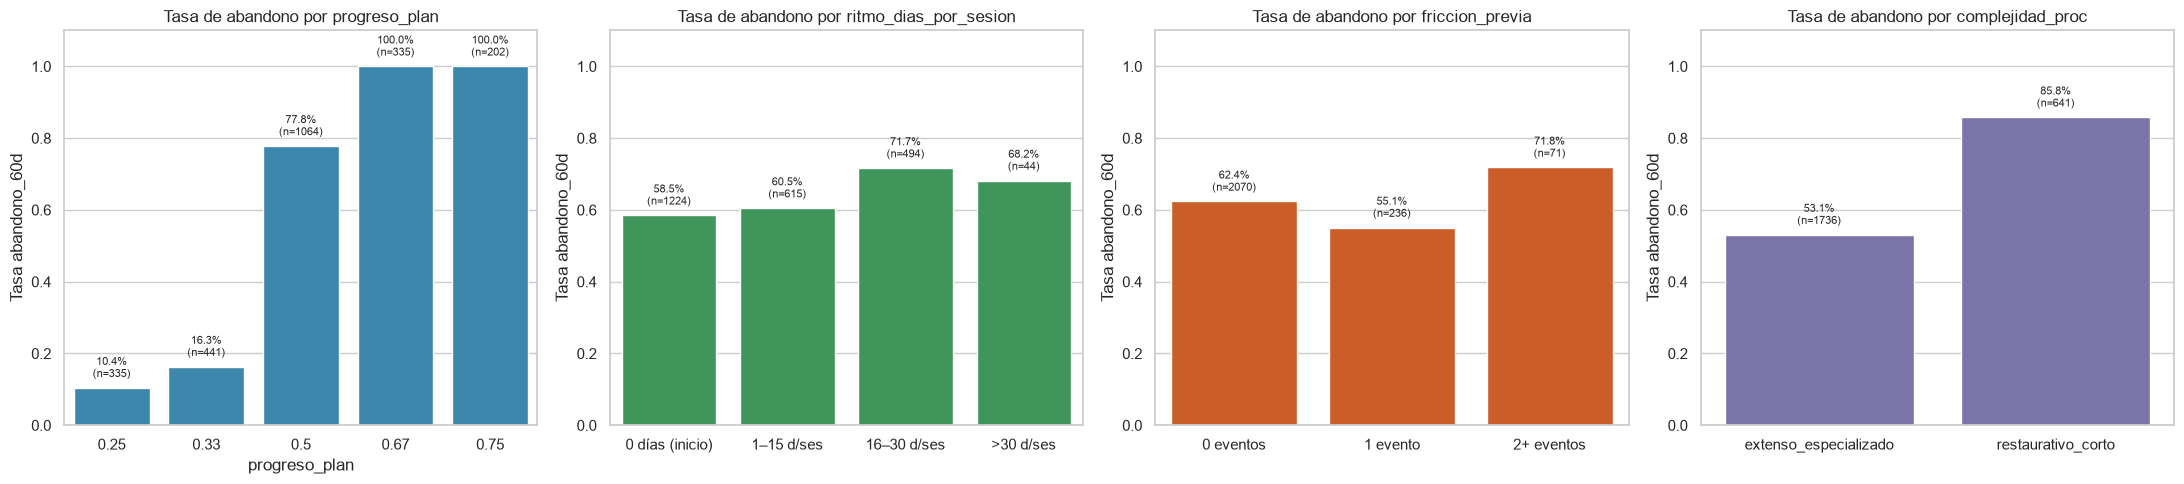

In [7]:
# 1. Tabla de evidencia estadística para features numéricas derivadas
filas_ev = []
for col in NUEVAS_NUM:
    rho, p_sp = stats.spearmanr(df_feat[col], df_feat[TARGET])
    g0 = df_feat.loc[df_feat[TARGET] == 0, col]
    g1 = df_feat.loc[df_feat[TARGET] == 1, col]
    _, p_mw = stats.mannwhitneyu(g0, g1, alternative="two-sided")
    filas_ev.append({
        "feature": col,
        "media_continua_0": round(g0.mean(), 3),
        "media_abandona_1": round(g1.mean(), 3),
        "mediana_0": round(g0.median(), 3),
        "mediana_1": round(g1.median(), 3),
        "spearman_rho": round(rho, 4),
        "p_value_mw": f"{p_mw:.2e}",
    })

display(pd.DataFrame(filas_ev).set_index("feature"))

# 2. Tabla de evidencia y Chi-cuadrado para la feature categórica derivada
ct_proc = pd.crosstab(df_feat["complejidad_proc"], df_feat[TARGET])
chi2, p_chi2, _, _ = stats.chi2_contingency(ct_proc)
res_cat = (
    df_feat.groupby("complejidad_proc")[TARGET]
    .agg(filas="size", tasa_abandono="mean")
    .round(4)
)
display(res_cat)
print(f"Prueba Chi-cuadrado (complejidad_proc vs {TARGET}): chi2 = {chi2:.2f} | p-value = {p_chi2:.2e}")

# 3. Panel gráfico 1x4 de tasa de abandono por feature derivada
fig, axes = plt.subplots(1, 4, figsize=(22, 5))

# (a) progreso_plan
g_prog = df_feat.groupby(df_feat["progreso_plan"].round(2))[TARGET].agg(["mean", "size"]).reset_index()
sns.barplot(data=g_prog, x="progreso_plan", y="mean", color="#2b8cbe", ax=axes[0])
axes[0].set_title("Tasa de abandono por progreso_plan")
axes[0].set_ylabel("Tasa abandono_60d")
axes[0].set_ylim(0, 1.1)
for i, r in g_prog.iterrows():
    axes[0].text(i, r["mean"] + 0.03, f"{r['mean']:.1%}\n(n={int(r['size'])})", ha="center", fontsize=8)

# (b) ritmo_dias_por_sesion (agrupado en tramos interpretables)
bins_ritmo = [-0.1, 0, 15, 30, 100]
labels_ritmo = ["0 días (inicio)", "1–15 d/ses", "16–30 d/ses", ">30 d/ses"]
df_feat["tramo_ritmo"] = pd.cut(df_feat["ritmo_dias_por_sesion"], bins=bins_ritmo, labels=labels_ritmo)
g_ritmo = df_feat.groupby("tramo_ritmo", observed=False)[TARGET].agg(["mean", "size"]).reset_index()
sns.barplot(data=g_ritmo, x="tramo_ritmo", y="mean", color="#31a354", ax=axes[1])
axes[1].set_title("Tasa de abandono por ritmo_dias_por_sesion")
axes[1].set_ylabel("Tasa abandono_60d")
axes[1].set_xlabel("")
axes[1].set_ylim(0, 1.1)
for i, r in g_ritmo.iterrows():
    axes[1].text(i, r["mean"] + 0.03, f"{r['mean']:.1%}\n(n={int(r['size'])})", ha="center", fontsize=8)

# (c) friccion_previa (0, 1, 2+)
df_feat["tramo_friccion"] = df_feat["friccion_previa"].clip(upper=2).map({0: "0 eventos", 1: "1 evento", 2: "2+ eventos"})
g_fric = df_feat.groupby("tramo_friccion")[TARGET].agg(["mean", "size"]).reindex(["0 eventos", "1 evento", "2+ eventos"]).reset_index()
sns.barplot(data=g_fric, x="tramo_friccion", y="mean", color="#e6550d", ax=axes[2])
axes[2].set_title("Tasa de abandono por friccion_previa")
axes[2].set_ylabel("Tasa abandono_60d")
axes[2].set_xlabel("")
axes[2].set_ylim(0, 1.1)
for i, r in g_fric.iterrows():
    axes[2].text(i, r["mean"] + 0.03, f"{r['mean']:.1%}\n(n={int(r['size'])})", ha="center", fontsize=8)

# (d) complejidad_proc
g_comp = df_feat.groupby("complejidad_proc")[TARGET].agg(["mean", "size"]).reset_index()
sns.barplot(data=g_comp, x="complejidad_proc", y="mean", color="#756bb1", ax=axes[3])
axes[3].set_title("Tasa de abandono por complejidad_proc")
axes[3].set_ylabel("Tasa abandono_60d")
axes[3].set_xlabel("")
axes[3].set_ylim(0, 1.1)
for i, r in g_comp.iterrows():
    axes[3].text(i, r["mean"] + 0.03, f"{r['mean']:.1%}\n(n={int(r['size'])})", ha="center", fontsize=8)

plt.tight_layout()
plt.show()

* **`progreso_plan`:** Es la variable nueva más fuerte ($\rho = 0.6819$, $p = 3.07 \times 10^{-242}$). Cuando el paciente lleva `25%–33%` del plan el abandono es bajo (`10.4%–16.3%`), pero sube a `77.8%` al llegar a la mitad (`0.50`) y alcanza `100.0%` desde el `67%` en adelante (`0.67–0.75`).
* **`ritmo_dias_por_sesion`:** Muestra una diferencia estadísticamente significativa entre grupos ($p = 1.19 \times 10^{-6}$, $\rho = 0.0996$). Quienes asisten el mismo día de inicio (`0 días`) abandonan en un `58.5%`, mientras que quienes espacian sus citas más de `15 días/sesión` suben a `68.2%–71.7%`.
* **`friccion_previa`:** Aunque su correlación lineal global es cercana a cero ($\rho = -0.0203$, $p = 0.322$) porque `0` y `1` evento se mantienen alrededor del promedio (`62.4%` y `55.1%`), captura un efecto extremo no lineal: al acumular **2 o más eventos previos**, el abandono sube a **71.8%** (`n = 71`).
* **`complejidad_proc`:** La prueba Chi-cuadrado confirma una separación muy marcada ($\chi^2 = 210.84$, $p = 9.03 \times 10^{-48}$): los procedimientos restaurativos cortos (`EXTRACT`, `FILL1`, `FILL2`) tienen un **85.8%** de abandono frente al **53.1%** en tratamientos extensos o especializados (`ROOT`, `CROWN`, `WHITEN`).

## 4. Justificación sin Fuga (*Data Leakage*), Codificación y Esquema Final

### 4.1 Auditoría temporal: ¿Por qué cada feature derivada está libre de fuga?

El momento de predicción ocurre **al cierre de cada sesión clínica atendida** (`fecha_realizada`), antes de programar o esperar la siguiente cita del plan:

1. **`progreso_plan = numero_sesion / sesiones_planificadas`:**
   * **Disponibilidad temporal:** `sesiones_planificadas` se define en la fecha de apertura del plan (`fecha_inicio_plan <= fecha_realizada`) y `numero_sesion` es el ordinal de la sesión que acaba de finalizar. Ninguno depende de eventos futuros.
   * **Tipo y transformación:** Numérica continua en `[0.25, 0.75]`. No requiere codificación categórica; pasa directa a modelos de árboles y se escala (`RobustScaler`) en modelos lineales y redes neuronales dentro del `Pipeline`.

2. **`ritmo_dias_por_sesion = dias_desde_inicio_plan / numero_sesion`:**
   * **Disponibilidad temporal:** `dias_desde_inicio_plan` (`fecha_realizada - fecha_inicio_plan`) queda completamente determinado al registrar el cierre de la consulta actual (`numero_sesion >= 1`). No usa fechas de citas posteriores.
   * **Tipo y transformación:** Numérica continua con cola derecha; se escala con `RobustScaler` dentro del `ColumnTransformer` ajustado exclusivamente con `train` (evitando fuga de estadísticos de escala).

3. **`friccion_previa = cancelaciones_previas + inasistencias_previas`:**
   * **Disponibilidad temporal:** Ambas variables base fueron calculadas en el pipeline de Spark mediante ventana histórica estrictamente anterior (`DIA_EVENTO < fecha_realizada`), excluyendo incluso eventos ocurridos el mismo día. Por tanto, su suma ya existe antes de iniciar la consulta.
   * **Tipo y transformación:** Numérica discreta; se escala con `RobustScaler` dentro del `ColumnTransformer`.

4. **`complejidad_proc` (`'restaurativo_corto'` vs. `'extenso_especializado'`):**
   * **Disponibilidad temporal:** Deriva de una regla determinista sobre `codigo_procedimiento`, atributo fijado al prescribir el plan de tratamiento (`fecha_inicio_plan`).
   * **Codificación categórica:** Al ser una variable **categórica nominal**, se codifica mediante **`OneHotEncoder(handle_unknown="ignore", sparse_output=False)`** dentro del `ColumnTransformer` ajustado solo en `train`, evitando imponer un orden numérico artificial.

---

### 4.2 Definición final de columnas para `pipeline_proyecto.py`

* **Features numéricas (`10`):**
  * Base (`7`): `duracion_estimada_min`, `numero_sesion`, `sesiones_planificadas`, `cancelaciones_previas`, `inasistencias_previas`, `dias_desde_inicio_plan`, `edad_en_atencion`. *(Se excluye `sesiones_previas` por colinealidad exacta `numero_sesion - 1`, y se excluyen `dia_semana_atencion` y `mes_atencion` por ruido estacional/calendario sin señal significativa en el EDA).*
  * Derivadas (`3`): `progreso_plan`, `ritmo_dias_por_sesion`, `friccion_previa`.
* **Features categóricas (`3`, codificadas con `OneHotEncoder(handle_unknown="ignore")`):**
  * Base (`2`): `codigo_procedimiento` (6 categorías), `odontologo_key` (5 profesionales tratados como categoría nominal).
  * Derivada (`1`): `complejidad_proc` (2 categorías).
* **Columnas excluidas explícitamente (`9`):**
  * Identificadores sin capacidad de generalización: `sesion_key`, `paciente_key`, `plan_tratamiento_id`, `cita_id`, `procedimiento_key`.
  * Redundante 1 a 1: `nombre_procedimiento` (duplicada de `codigo_procedimiento`).
  * Marcas temporales crudas usadas para ordenamiento/partición cronológica, no como regresores directos: `fecha_realizada`, `fecha_inicio_plan`.
  * Variables estacionales descartadas: `dia_semana_atencion`, `mes_atencion`.

In [8]:
FEATURES_NUM = [
    "duracion_estimada_min",
    "numero_sesion",
    "sesiones_planificadas",
    "cancelaciones_previas",
    "inasistencias_previas",
    "dias_desde_inicio_plan",
    "edad_en_atencion",
    "progreso_plan",
    "ritmo_dias_por_sesion",
    "friccion_previa",
]

FEATURES_CAT = [
    "codigo_procedimiento",
    "odontologo_key",
    "complejidad_proc",
]

FEATURES_FINALES = FEATURES_NUM + FEATURES_CAT

# Comprobaciones automáticas de integridad antes de pasar a pipeline_proyecto.py
assert len(FEATURES_FINALES) == len(set(FEATURES_FINALES)), "Hay features duplicadas"
assert TARGET not in FEATURES_FINALES, "Fuga: el target está en las features"
assert not any(c in FEATURES_FINALES for c in ["sesion_key", "paciente_key", "plan_tratamiento_id", "cita_id", "es_ultima_observada"]), "Fuga o ID detectado"
assert df_feat[FEATURES_FINALES].isna().sum().sum() == 0, "Existen valores nulos en las features finales"

print(f"Total features seleccionadas: {len(FEATURES_FINALES)} ({len(FEATURES_NUM)} numéricas + {len(FEATURES_CAT)} categóricas)")
print("Numéricas :", FEATURES_NUM)
print("Categóricas:", FEATURES_CAT)
df_feat[FEATURES_FINALES + [TARGET]].head()

Total features seleccionadas: 13 (10 numéricas + 3 categóricas)
Numéricas : ['duracion_estimada_min', 'numero_sesion', 'sesiones_planificadas', 'cancelaciones_previas', 'inasistencias_previas', 'dias_desde_inicio_plan', 'edad_en_atencion', 'progreso_plan', 'ritmo_dias_por_sesion', 'friccion_previa']
Categóricas: ['codigo_procedimiento', 'odontologo_key', 'complejidad_proc']


,duracion_estimada_min,numero_sesion,sesiones_planificadas,cancelaciones_previas,inasistencias_previas,dias_desde_inicio_plan,edad_en_atencion,progreso_plan,ritmo_dias_por_sesion,friccion_previa,codigo_procedimiento,odontologo_key,complejidad_proc,abandono_60d
0,60,1,2,0,0,0,72,0.500000,0.0,0,WHITEN,2,extenso_especializado,1
1,90,1,4,1,0,23,52,0.250000,23.0,1,ROOT,4,extenso_especializado,0
2,90,2,4,2,0,61,52,0.500000,30.5,2,ROOT,4,extenso_especializado,0
3,75,1,3,0,0,0,52,0.333333,0.0,0,CROWN,4,extenso_especializado,0
4,75,2,3,0,0,35,52,0.666667,17.5,0,CROWN,4,extenso_especializado,1


Todas las aserciones de integridad, ausencia de nulos y prevención de fuga de datos pasaron correctamente. El conjunto de **13 features** (`10` numéricas y `3` categóricas) queda listo para encapsularse de forma reproducible dentro de `modelado/pipeline_proyecto.py`.